<a href="https://colab.research.google.com/github/AayushiSud06/HealthTrace.AI/blob/main/notebooks/HealthTrace.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



##**HealthTrace**: Multimodal AI for Unified Patient Health Records



In [2]:

!pip install -q pandas numpy matplotlib seaborn scikit-learn \
    opencv-python-headless pytesseract pdfplumber \
    google-genai sentence-transformers


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [3]:

!apt-get update -qq
!apt-get install -y -qq tesseract-ocr


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


In [4]:

import os
import zipfile
import glob
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import pytesseract

from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("HealthTrace environment initialized successfully!")
print("OpenCV version:", cv2.__version__)
print("Pandas version:", pd.__version__)
print("Tesseract version:", pytesseract.get_tesseract_version())


HealthTrace environment initialized successfully!
OpenCV version: 5.0.0
Pandas version: 2.2.3
Tesseract version: 5.3.4


In [5]:

from google.colab import files

uploaded = files.upload()

zip_files = [f for f in uploaded.keys() if f.endswith(".zip")]

if not zip_files:
    raise ValueError("Please upload the Synthea CSV ZIP file.")

zip_path = zip_files[0]

os.makedirs("/content/healthtrace_data", exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("/content/healthtrace_data")

print("Dataset extracted successfully!")


Saving synthea_sample_data_csv_nov2021.zip to synthea_sample_data_csv_nov2021.zip
Dataset extracted successfully!


In [6]:

csv_files = glob.glob(
    "/content/healthtrace_data/**/*.csv",
    recursive=True
)

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))


CSV files found: 18
medications.csv
organizations.csv
careplans.csv
devices.csv
observations.csv
procedures.csv
imaging_studies.csv
supplies.csv
providers.csv
conditions.csv
allergies.csv
payer_transitions.csv
payers.csv
claims.csv
encounters.csv
immunizations.csv
patients.csv
claims_transactions.csv


In [7]:

data = {}

for file in csv_files:
    table_name = os.path.basename(file).replace(".csv", "").lower()
    data[table_name] = pd.read_csv(file, low_memory=False)

print("\nLoaded tables:")

for name, df in data.items():
    print(f"{name}: {df.shape}")



Loaded tables:
medications: (56430, 13)
organizations: (1127, 11)
careplans: (3931, 9)
devices: (89, 7)
observations: (531144, 9)
procedures: (83823, 9)
imaging_studies: (151637, 13)
supplies: (1573, 6)
providers: (5056, 12)
conditions: (38094, 6)
allergies: (794, 15)
payer_transitions: (53101, 8)
payers: (10, 21)
claims: (117889, 31)
encounters: (61459, 15)
immunizations: (17009, 6)
patients: (1163, 25)
claims_transactions: (711238, 33)


In [8]:

required_tables = [
    "patients",
    "encounters",
    "conditions",
    "medications",
    "allergies",
    "observations",
    "procedures"
]

for table in required_tables:
    if table in data:
        print(f"\n{'='*50}")
        print(f"TABLE: {table.upper()}")
        print("Shape:", data[table].shape)
        print("Columns:", data[table].columns.tolist())
    else:
        print(f"\nWARNING: {table} is missing")



TABLE: PATIENTS
Shape: (1163, 25)
Columns: ['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE']

TABLE: ENCOUNTERS
Shape: (61459, 15)
Columns: ['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

TABLE: CONDITIONS
Shape: (38094, 6)
Columns: ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION']

TABLE: MEDICATIONS
Shape: (56430, 13)
Columns: ['START', 'STOP', 'PATIENT', 'PAYER', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'PAYER_COVERAGE', 'DISPENSES', 'TOTALCOST', 'REASONCODE', 'REASONDESCRIPTION']

TABLE: ALLERGIES
Shape: (794, 15)
Columns: ['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'SYSTEM', 

## EDA and data understanding

In [9]:

for table in [
    "patients",
    "encounters",
    "conditions",
    "medications",
    "allergies",
    "observations"
]:
    df = data[table]

    print(f"\n{table.upper()}")
    missing = (
        df.isnull()
        .sum()
        .sort_values(ascending=False)
    )

    display(
        pd.DataFrame({
            "Missing Values": missing,
            "Missing Percentage": (
                missing / len(df) * 100
            ).round(2)
        }).head(10)
    )



PATIENTS


,Missing Values,Missing Percentage
SUFFIX,1147,98.62
DEATHDATE,1000,85.98
MAIDEN,832,71.54
ZIP,545,46.86
MARITAL,384,33.02
PASSPORT,276,23.73
PREFIX,245,21.07
DRIVERS,215,18.49
Id,0,0.00
LAST,0,0.00



ENCOUNTERS


,Missing Values,Missing Percentage
REASONCODE,45502,74.04
REASONDESCRIPTION,45502,74.04
Id,0,0.00
PATIENT,0,0.00
ORGANIZATION,0,0.00
START,0,0.00
STOP,0,0.00
PAYER,0,0.00
PROVIDER,0,0.00
ENCOUNTERCLASS,0,0.00



CONDITIONS


,Missing Values,Missing Percentage
STOP,8169,21.44
START,0,0.00
PATIENT,0,0.00
ENCOUNTER,0,0.00
CODE,0,0.00
DESCRIPTION,0,0.00


... (2 outputs left out)


ALLERGIES


,Missing Values,Missing Percentage
STOP,794,100.00
SEVERITY2,535,67.38
DESCRIPTION2,535,67.38
REACTION2,535,67.38
DESCRIPTION1,384,48.36
SEVERITY1,384,48.36
REACTION1,384,48.36
DESCRIPTION,0,0.00
SYSTEM,0,0.00
CODE,0,0.00



OBSERVATIONS


,Missing Values,Missing Percentage
UNITS,185017,34.83
CATEGORY,31662,5.96
ENCOUNTER,31662,5.96
DATE,0,0.00
PATIENT,0,0.00
CODE,0,0.00
DESCRIPTION,0,0.00
VALUE,0,0.00
TYPE,0,0.00


In [10]:

def get_column(df, name):
    matches = [
        col for col in df.columns
        if col.lower() == name.lower()
    ]

    if not matches:
        raise KeyError(
            f"Column '{name}' not found. "
            f"Available columns: {df.columns.tolist()}"
        )

    return matches[0]


patient_id_col = get_column(data["patients"], "Id")

tables_to_check = [
    "encounters",
    "conditions",
    "medications",
    "allergies",
    "observations",
    "procedures",
    "imaging_studies"
]

for table in tables_to_check:
    df = data[table]
    patient_col = get_column(df, "PATIENT")

    valid_ids = set(data["patients"][patient_id_col])

    matched = df[patient_col].isin(valid_ids).sum()

    print(
        f"{table}: {matched}/{len(df)} "
        f"records linked to known patients"
    )


encounters: 61459/61459 records linked to known patients
conditions: 38094/38094 records linked to known patients
medications: 56430/56430 records linked to known patients
allergies: 794/794 records linked to known patients
observations: 531144/531144 records linked to known patients
procedures: 83823/83823 records linked to known patients
imaging_studies: 151637/151637 records linked to known patients


In [11]:

patients = data["patients"].copy()

patient_id_col = get_column(patients, "Id")

patient_summary = patients[
    [patient_id_col]
].copy()

patient_summary = patient_summary.rename(
    columns={patient_id_col: "PATIENT_ID"}
)

record_tables = {
    "encounters": "encounters",
    "diagnoses": "conditions",
    "medications": "medications",
    "allergies": "allergies",
    "observations": "observations",
    "procedures": "procedures",
    "imaging": "imaging_studies"
}

for label, table in record_tables.items():

    df = data[table]
    patient_col = get_column(df, "PATIENT")

    counts = df.groupby(patient_col).size()

    patient_summary[label] = (
        patient_summary["PATIENT_ID"]
        .map(counts)
        .fillna(0)
        .astype(int)
    )

patient_summary["TOTAL_RECORDS"] = (
    patient_summary[list(record_tables.keys())]
    .sum(axis=1)
)

patient_summary = patient_summary.sort_values(
    by=["encounters", "observations", "medications"],
    ascending=False
)

display(patient_summary.head(15))


,PATIENT_ID,encounters,diagnoses,medications,allergies,observations,procedures,imaging,TOTAL_RECORDS
256,ef167059-cef0-12c4-49db-993ca3a20c01,1563,328,1988,0,9297,1532,0,14708
739,a1c127d9-d31e-36b1-2a3e-3014be9bfdf0,838,186,1235,0,3125,362,1,5747
513,e23c7a6e-6ef2-3932-1361-b73b4c8a3961,705,460,2117,0,4406,799,0,8487
626,8c6ae452-5f8c-9ff6-006d-c6c860acf5cd,638,352,808,0,4062,496,1,6357
926,e6178711-3936-e332-814d-19d8851e314d,497,355,1747,0,3847,566,0,7012
861,139f1206-227d-4cf1-2bea-7d3154516bdf,447,435,838,0,4100,490,1,6311
413,55c5b8d3-99d0-58ad-8444-e42bb81bd5c7,412,228,825,0,4317,801,0,6583
772,562e7d26-9dfb-95f2-0815-3c20129955b8,401,186,883,3,3743,302,0,5518
662,e0b4bd84-4df2-d30c-cd67-a9daee769602,390,201,538,0,3703,497,1,5330
690,864b2fa0-78e3-88c6-2ce2-ba3aea72236c,383,258,1042,0,4522,424,0,6629


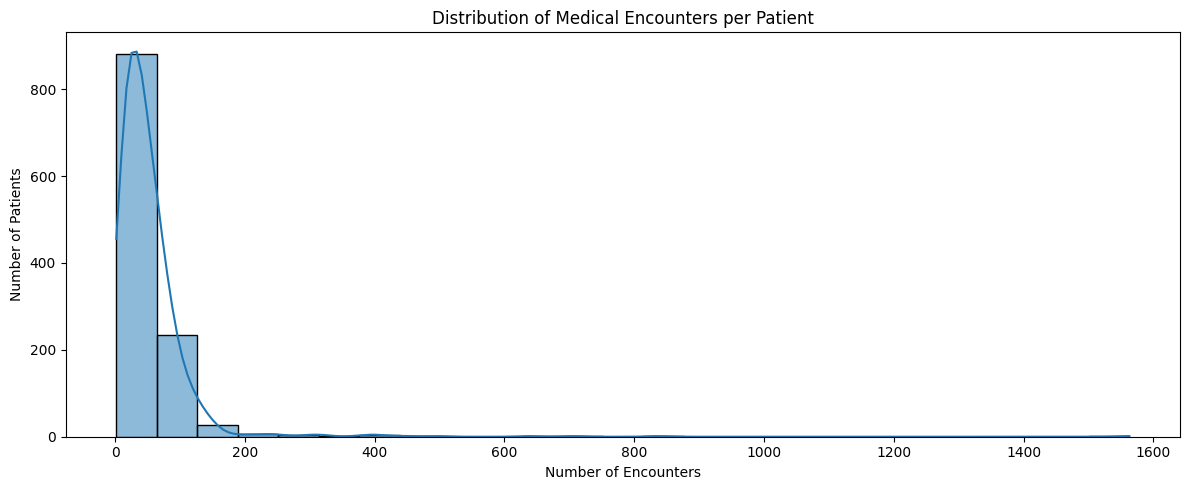

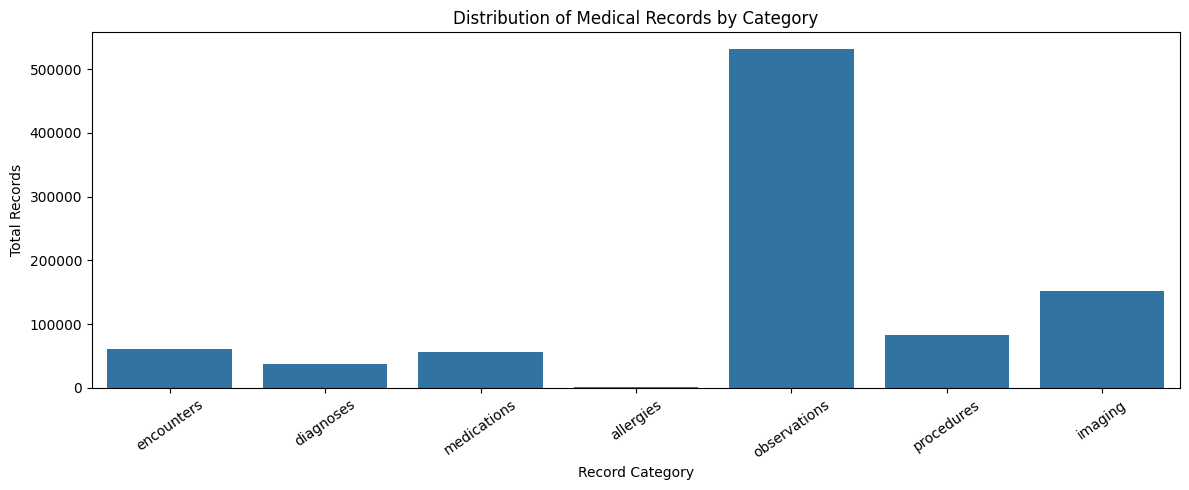

In [12]:

plt.figure(figsize=(12, 5))

sns.histplot(
    patient_summary["encounters"],
    bins=25,
    kde=True
)

plt.title("Distribution of Medical Encounters per Patient")
plt.xlabel("Number of Encounters")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()


record_counts = patient_summary[
    list(record_tables.keys())
].sum()

plt.figure(figsize=(12, 5))

sns.barplot(
    x=record_counts.index,
    y=record_counts.values
)

plt.title("Distribution of Medical Records by Category")
plt.xlabel("Record Category")
plt.ylabel("Total Records")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


In [13]:

patient_summary["SELECTION_SCORE"] = (
    3 * (patient_summary["encounters"] >= 3).astype(int)
    + 2 * (patient_summary["diagnoses"] >= 1).astype(int)
    + 2 * (patient_summary["medications"] >= 1).astype(int)
    + 2 * (patient_summary["observations"] >= 5).astype(int)
    + 1 * (patient_summary["allergies"] >= 1).astype(int)
    + 1 * (patient_summary["procedures"] >= 1).astype(int)
    + 1 * (patient_summary["imaging"] >= 1).astype(int)
)

patient_summary = patient_summary.sort_values(
    ["SELECTION_SCORE", "TOTAL_RECORDS"],
    ascending=False
)

display(patient_summary.head(10))

selected_patient_id = (
    patient_summary.iloc[0]["PATIENT_ID"]
)

print("Selected Patient ID:", selected_patient_id)
print(
    "Selection Score:",
    patient_summary.iloc[0]["SELECTION_SCORE"]
)


,PATIENT_ID,encounters,diagnoses,medications,allergies,observations,procedures,imaging,TOTAL_RECORDS,SELECTION_SCORE
309,03e502b6-b810-06c1-7d65-83db077ed3ee,108,29,90,10,1840,194,12173,14444,12
390,0e78dfee-9af0-046c-39bb-33fdcb910976,83,53,163,3,1085,113,5513,7013,12
642,a8b166c9-23da-d720-b0e1-296944f432dc,152,132,231,1,2856,317,1,3690,12
545,3b26d1ac-6443-060d-d502-b93b8d82ccc2,114,74,286,2,728,108,4,1316,12
590,ac58e6c6-b5d7-8fe7-a0f3-452885f7b560,200,37,29,3,909,93,6,1277,12
349,153c68e6-08e5-a751-1f6b-4439d279681d,124,64,255,7,637,74,1,1162,12
631,c07fdd29-a5c1-6e59-32f4-ce41a4633cd5,118,77,202,7,616,77,2,1099,12
857,b755085e-cb18-f1f0-d5f3-477b850a231b,80,68,22,1,837,79,1,1088,12
549,7bc66758-5d59-0b38-1532-29a33fa146c1,158,96,103,1,646,78,1,1083,12
937,c4292552-ab46-dd25-c7ee-61596965f2e2,111,48,21,8,784,66,7,1045,12


Selected Patient ID: 03e502b6-b810-06c1-7d65-83db077ed3ee
Selection Score: 12


In [14]:
def get_patient_records(table_name, patient_id):
    df = data[table_name]
    patient_col = get_column(df, "PATIENT")
    return df[df[patient_col] == patient_id].copy()


patient_records = {}

for label, table_name in record_tables.items():
    patient_records[label] = get_patient_records(
        table_name,
        selected_patient_id
    )

for label, df in patient_records.items():
    print(f"{label}: {len(df)} records")

encounters: 108 records
diagnoses: 29 records
medications: 90 records
allergies: 10 records
observations: 1840 records
procedures: 194 records
imaging: 12173 records


In [15]:
timeline_frames = []

timeline_config = {
    "encounters": "ENCOUNTER",
    "diagnoses": "DIAGNOSIS",
    "medications": "MEDICATION",
    "allergies": "ALLERGY",
    "observations": "LAB / OBSERVATION",
    "procedures": "PROCEDURE",
    "imaging": "IMAGING"
}

for table, category in timeline_config.items():

    df = patient_records[table].copy()

    if df.empty:
        continue

    date_candidates = ["START", "DATE", "STOP"]

    actual_date_col = next(
        (col for col in df.columns
         if col.upper() in date_candidates),
        None
    )

    if actual_date_col is None:
        print(f"Skipping {table}: no date column found")
        continue

    description_col = next(
        (col for col in df.columns
         if col.upper() in ["DESCRIPTION", "CODE", "NAME"]),
        None
    )

    dates = pd.to_datetime(
        df[actual_date_col],
        errors="coerce",
        utc=True
    ).dt.tz_localize(None)

    temp = pd.DataFrame({
        "DATE": dates,
        "CATEGORY": category,
        "DETAIL": (
            df[description_col].fillna("Unknown").astype(str)
            if description_col
            else category
        )
    })

    timeline_frames.append(temp)

if timeline_frames:

    patient_timeline = pd.concat(
        timeline_frames,
        ignore_index=True
    )

    patient_timeline = (
        patient_timeline
        .dropna(subset=["DATE"])
        .sort_values("DATE")
        .reset_index(drop=True)
    )

    display(patient_timeline.head(30))

    print("\nTotal timeline events:", len(patient_timeline))

else:
    print("No timeline records could be created.")

,DATE,CATEGORY,DETAIL
0,1969-01-06 08:56:17,ENCOUNTER,185347001
1,1969-01-24 00:00:00,ALLERGY,111088007
2,1969-01-24 00:00:00,ALLERGY,84489001
3,1969-01-24 00:00:00,ALLERGY,260147004
4,1969-01-24 00:00:00,ALLERGY,264287008
5,1969-01-24 00:00:00,ALLERGY,256277009
6,1969-01-24 00:00:00,ALLERGY,7984
7,1969-01-24 00:00:00,ALLERGY,256355007
8,1969-01-24 00:00:00,ALLERGY,102263004
9,1969-01-24 00:00:00,ALLERGY,412071004



Total timeline events: 14444


##Synthetic medical document generation

In [16]:
for category, df in patient_records.items():
    print("\n" + "="*60)
    print(category.upper())
    print("Records:", len(df))

    if not df.empty:
        display(df.head(3))


ENCOUNTERS
Records: 108


,Id,START,STOP,PATIENT,ORGANIZATION,PROVIDER,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
15218,2d10a4f8-62dc-ee36-1902-d2336e360639,1969-01-06T08:56:17Z,1969-01-06T09:11:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,5d4b9df1-93ae-3bc9-b680-03249990e558,da3170c9-722b-3ec4-b0a7-c8047575c63a,047f6ec3-6215-35eb-9608-f9dda363a44c,ambulatory,185347001,Encounter for problem,77.49,77.49,0.0,NaN,NaN
15220,86316741-a100-cd8c-9d18-3a1256979b95,1969-01-24T17:56:17Z,1969-01-24T18:11:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,5d4b9df1-93ae-3bc9-b680-03249990e558,da3170c9-722b-3ec4-b0a7-c8047575c63a,047f6ec3-6215-35eb-9608-f9dda363a44c,ambulatory,185347001,Encounter for problem,77.49,77.49,0.0,NaN,NaN
15221,668fe595-31e3-efea-4f04-a7724796ab7c,1972-05-17T02:56:17Z,1972-05-17T03:11:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,5d4b9df1-93ae-3bc9-b680-03249990e558,da3170c9-722b-3ec4-b0a7-c8047575c63a,4d71f845-a6a9-3c39-b242-14d25ef86a8d,ambulatory,185345009,Encounter for symptom,77.49,77.49,0.0,232353008.0,Perennial allergic rhinitis with seasonal vari...



DIAGNOSES
Records: 29


,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION
8939,1984-11-23,NaN,03e502b6-b810-06c1-7d65-83db077ed3ee,42e4d73e-1134-6636-85e9-5d44390c15e9,160968000,Risk activity involvement (finding)
8940,1985-11-29,NaN,03e502b6-b810-06c1-7d65-83db077ed3ee,6326f34e-56ca-8e29-3a9f-ffb41278557a,224295006,Only received primary school education (finding)
8941,1985-11-29,NaN,03e502b6-b810-06c1-7d65-83db077ed3ee,6326f34e-56ca-8e29-3a9f-ffb41278557a,73438004,Unemployed (finding)



MEDICATIONS
Records: 90


,START,STOP,PATIENT,PAYER,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,PAYER_COVERAGE,DISPENSES,TOTALCOST,REASONCODE,REASONDESCRIPTION
11884,1972-05-17T02:56:17Z,NaN,03e502b6-b810-06c1-7d65-83db077ed3ee,4d71f845-a6a9-3c39-b242-14d25ef86a8d,668fe595-31e3-efea-4f04-a7724796ab7c,477045,Chlorpheniramine Maleate 2 MG/ML Oral Solution,4.75,0.0,602,2859.50,NaN,NaN
11885,2009-11-07T02:56:17Z,2021-11-04T02:56:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,047f6ec3-6215-35eb-9608-f9dda363a44c,b5fdf6e2-d512-2282-ad32-193c720ad400,314231,Simvastatin 10 MG Oral Tablet,0.02,0.0,10,0.20,55822004.0,Hyperlipidemia
11886,2010-11-07T02:56:17Z,2011-11-07T02:56:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,047f6ec3-6215-35eb-9608-f9dda363a44c,f02d3663-ef0f-1819-d11f-18ae58d98cff,314231,Simvastatin 10 MG Oral Tablet,0.02,0.0,12,0.24,55822004.0,Hyperlipidemia


... (4 outputs left out)


PROCEDURES
Records: 194


,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
21434,2012-01-21T02:56:17Z,2012-01-21T03:14:13Z,03e502b6-b810-06c1-7d65-83db077ed3ee,c7db1529-f174-f21f-7422-b12d6440e554,76601001,Intramuscular injection,2456.77,NaN,NaN
21435,2012-04-21T02:56:17Z,2012-04-21T03:09:04Z,03e502b6-b810-06c1-7d65-83db077ed3ee,6626ac24-8567-8452-881d-f5b4d5c29ccd,76601001,Intramuscular injection,3956.92,NaN,NaN
21436,2012-07-21T02:56:17Z,2012-07-21T03:11:14Z,03e502b6-b810-06c1-7d65-83db077ed3ee,d7e3cf71-dfe1-8cf3-4169-3cf45649b2ba,76601001,Intramuscular injection,3172.67,NaN,NaN



IMAGING
Records: 12173


,Id,DATE,PATIENT,ENCOUNTER,SERIES_UID,BODYSITE_CODE,BODYSITE_DESCRIPTION,MODALITY_CODE,MODALITY_DESCRIPTION,INSTANCE_UID,SOP_CODE,SOP_DESCRIPTION,PROCEDURE_CODE
36198,e56866c7-c28b-6944-bd2f-8eb1bee4e51b,2015-04-03T02:56:17Z,03e502b6-b810-06c1-7d65-83db077ed3ee,70a62104-aa1c-23c0-ede9-f415a48b94cd,1.2.840.99999999.1.99738315.1428029777880,8205005,Wrist,DX,Digital Radiography,1.2.840.99999999.1.1.93083651.1428029777880,1.2.840.10008.5.1.4.1.1.1.1,Digital X-Ray Image Storage,60027007
36199,7f54d074-1563-27b3-859b-0bc8eb8f6416,2019-05-16T19:29:07Z,03e502b6-b810-06c1-7d65-83db077ed3ee,4eb71790-9084-f515-74a0-27ed49d450a9,1.2.840.99999999.1.99952624.1558034947880,51185008,Thoracic structure (body structure),CT,Computed Tomography,1.2.840.99999999.1.1.77525457.1558034947880,1.2.840.10008.5.1.4.1.1.2,CT Image Storage,16335031000119103
36200,7f54d074-1563-27b3-859b-0bc8eb8f6416,2019-05-16T19:29:07Z,03e502b6-b810-06c1-7d65-83db077ed3ee,4eb71790-9084-f515-74a0-27ed49d450a9,1.2.840.99999999.1.99952624.1558034947880,51185008,Thoracic structure (body structure),CT,Computed Tomography,1.2.840.99999999.1.2.76865093.1558034947880,1.2.840.10008.5.1.4.1.1.2,CT Image Storage,16335031000119103


In [17]:
!pip install -q reportlab

In [18]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
from reportlab.lib.enums import TA_CENTER
from datetime import datetime
import os

In [19]:
styles = getSampleStyleSheet()

title_style = styles["Title"]
heading_style = styles["Heading2"]
normal_style = styles["BodyText"]

def safe_value(value):
    if pd.isna(value):
        return "Not available"
    return str(value)


def create_medical_report(patient_id, patient_records, output_path):

    story = []

    patient_df = data["patients"]

    id_col = get_column(patient_df, "Id")

    patient_info = patient_df[
        patient_df[id_col] == patient_id
    ].iloc[0]

    story.append(Paragraph(
        "HEALTHTRACE - PATIENT MEDICAL HISTORY",
        title_style
    ))

    story.append(Spacer(1, 15))

    story.append(Paragraph(
        "Patient Information",
        heading_style
    ))

    demographics = [
        ["Field", "Information"],
        ["Patient ID", safe_value(patient_id)],
        ["Birth Date", safe_value(patient_info.get("BIRTHDATE"))],
        ["Gender", safe_value(patient_info.get("GENDER"))],
        ["City", safe_value(patient_info.get("CITY"))],
        ["State", safe_value(patient_info.get("STATE"))]
    ]

    table = Table(demographics, colWidths=[150, 300])

    table.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), colors.lightblue),
        ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
        ("PADDING", (0,0), (-1,-1), 7)
    ]))

    story.append(table)
    story.append(Spacer(1, 20))

    sections = {
        "encounters": "Hospital Encounters",
        "diagnoses": "Medical Conditions",
        "medications": "Medication History",
        "allergies": "Allergy Information",
        "observations": "Laboratory and Clinical Observations",
        "procedures": "Medical Procedures",
        "imaging": "Imaging Records"
    }

    for category, heading in sections.items():

        df = patient_records[category]

        story.append(Paragraph(heading, heading_style))

        if df.empty:
            story.append(Paragraph(
                "No records available.",
                normal_style
            ))
            story.append(Spacer(1, 10))
            continue

        for _, row in df.head(30).iterrows():

            description = row.get(
                "DESCRIPTION",
                row.get("VALUE", row.get("CODE", "Record"))
            )

            start = row.get(
                "START",
                row.get("DATE", "Date not available")
            )

            detail = (
                f"<b>Date:</b> {safe_value(start)}<br/>"
                f"<b>Details:</b> {safe_value(description)}"
            )

            story.append(Paragraph(detail, normal_style))
            story.append(Spacer(1, 7))

        story.append(Spacer(1, 12))

    doc = SimpleDocTemplate(
        output_path,
        pagesize=A4,
        rightMargin=40,
        leftMargin=40,
        topMargin=40,
        bottomMargin=40
    )

    doc.build(story)

    print("Medical report generated:", output_path)

In [20]:
os.makedirs("/content/healthtrace_reports", exist_ok=True)

report_path = (
    "/content/healthtrace_reports/"
    "patient_medical_history.pdf"
)

create_medical_report(
    selected_patient_id,
    patient_records,
    report_path
)

Medical report generated: /content/healthtrace_reports/patient_medical_history.pdf


In [23]:
from google.colab import files

files.download(report_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##OCR and document preprocessing

In [24]:
import pdfplumber

extracted_text = ""

with pdfplumber.open(report_path) as pdf:

    for page_number, page in enumerate(pdf.pages):

        page_text = page.extract_text()

        if page_text:
            extracted_text += page_text + "\n"

print("Extracted Text:\n")
print(extracted_text[:4000])

print("\nTotal Characters:", len(extracted_text))

Extracted Text:

HEALTHTRACE - PATIENT MEDICAL HISTORY
Patient Information
Field Information
Patient ID 03e502b6-b810-06c1-7d65-83db077ed3ee
Birth Date 1967-10-06
Gender F
City Holyoke
State Massachusetts
Hospital Encounters
Date: 1969-01-06T08:56:17Z
Details: Encounter for problem
Date: 1969-01-24T17:56:17Z
Details: Encounter for problem
Date: 1972-05-17T02:56:17Z
Details: Encounter for symptom
Date: 1984-11-24T02:56:17Z
Details: Well child visit (procedure)
Date: 1985-11-30T02:56:17Z
Details: General examination of patient (procedure)
Date: 1986-12-06T02:56:17Z
Details: General examination of patient (procedure)
Date: 1995-12-16T02:56:17Z
Details: General examination of patient (procedure)
Date: 2004-12-25T02:56:17Z
Details: General examination of patient (procedure)
Date: 2007-10-13T02:56:17Z
Details: General examination of patient (procedure)
Date: 2009-10-17T02:56:17Z
Details: General examination of patient (procedure)
Date: 2009-11-07T02:56:17Z
Details: Follow-up encounter
Date: 

In [25]:
!pip install -q pdf2image
!apt-get install -y -qq poppler-utils

Selecting previously unselected package poppler-utils.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../poppler-utils_24.02.0-1ubuntu9.11_amd64.deb ...
Unpacking poppler-utils (24.02.0-1ubuntu9.11) ...
Setting up poppler-utils (24.02.0-1ubuntu9.11) ...
Processing triggers for man-db (2.12.0-4build2) ...


Total pages converted: 11


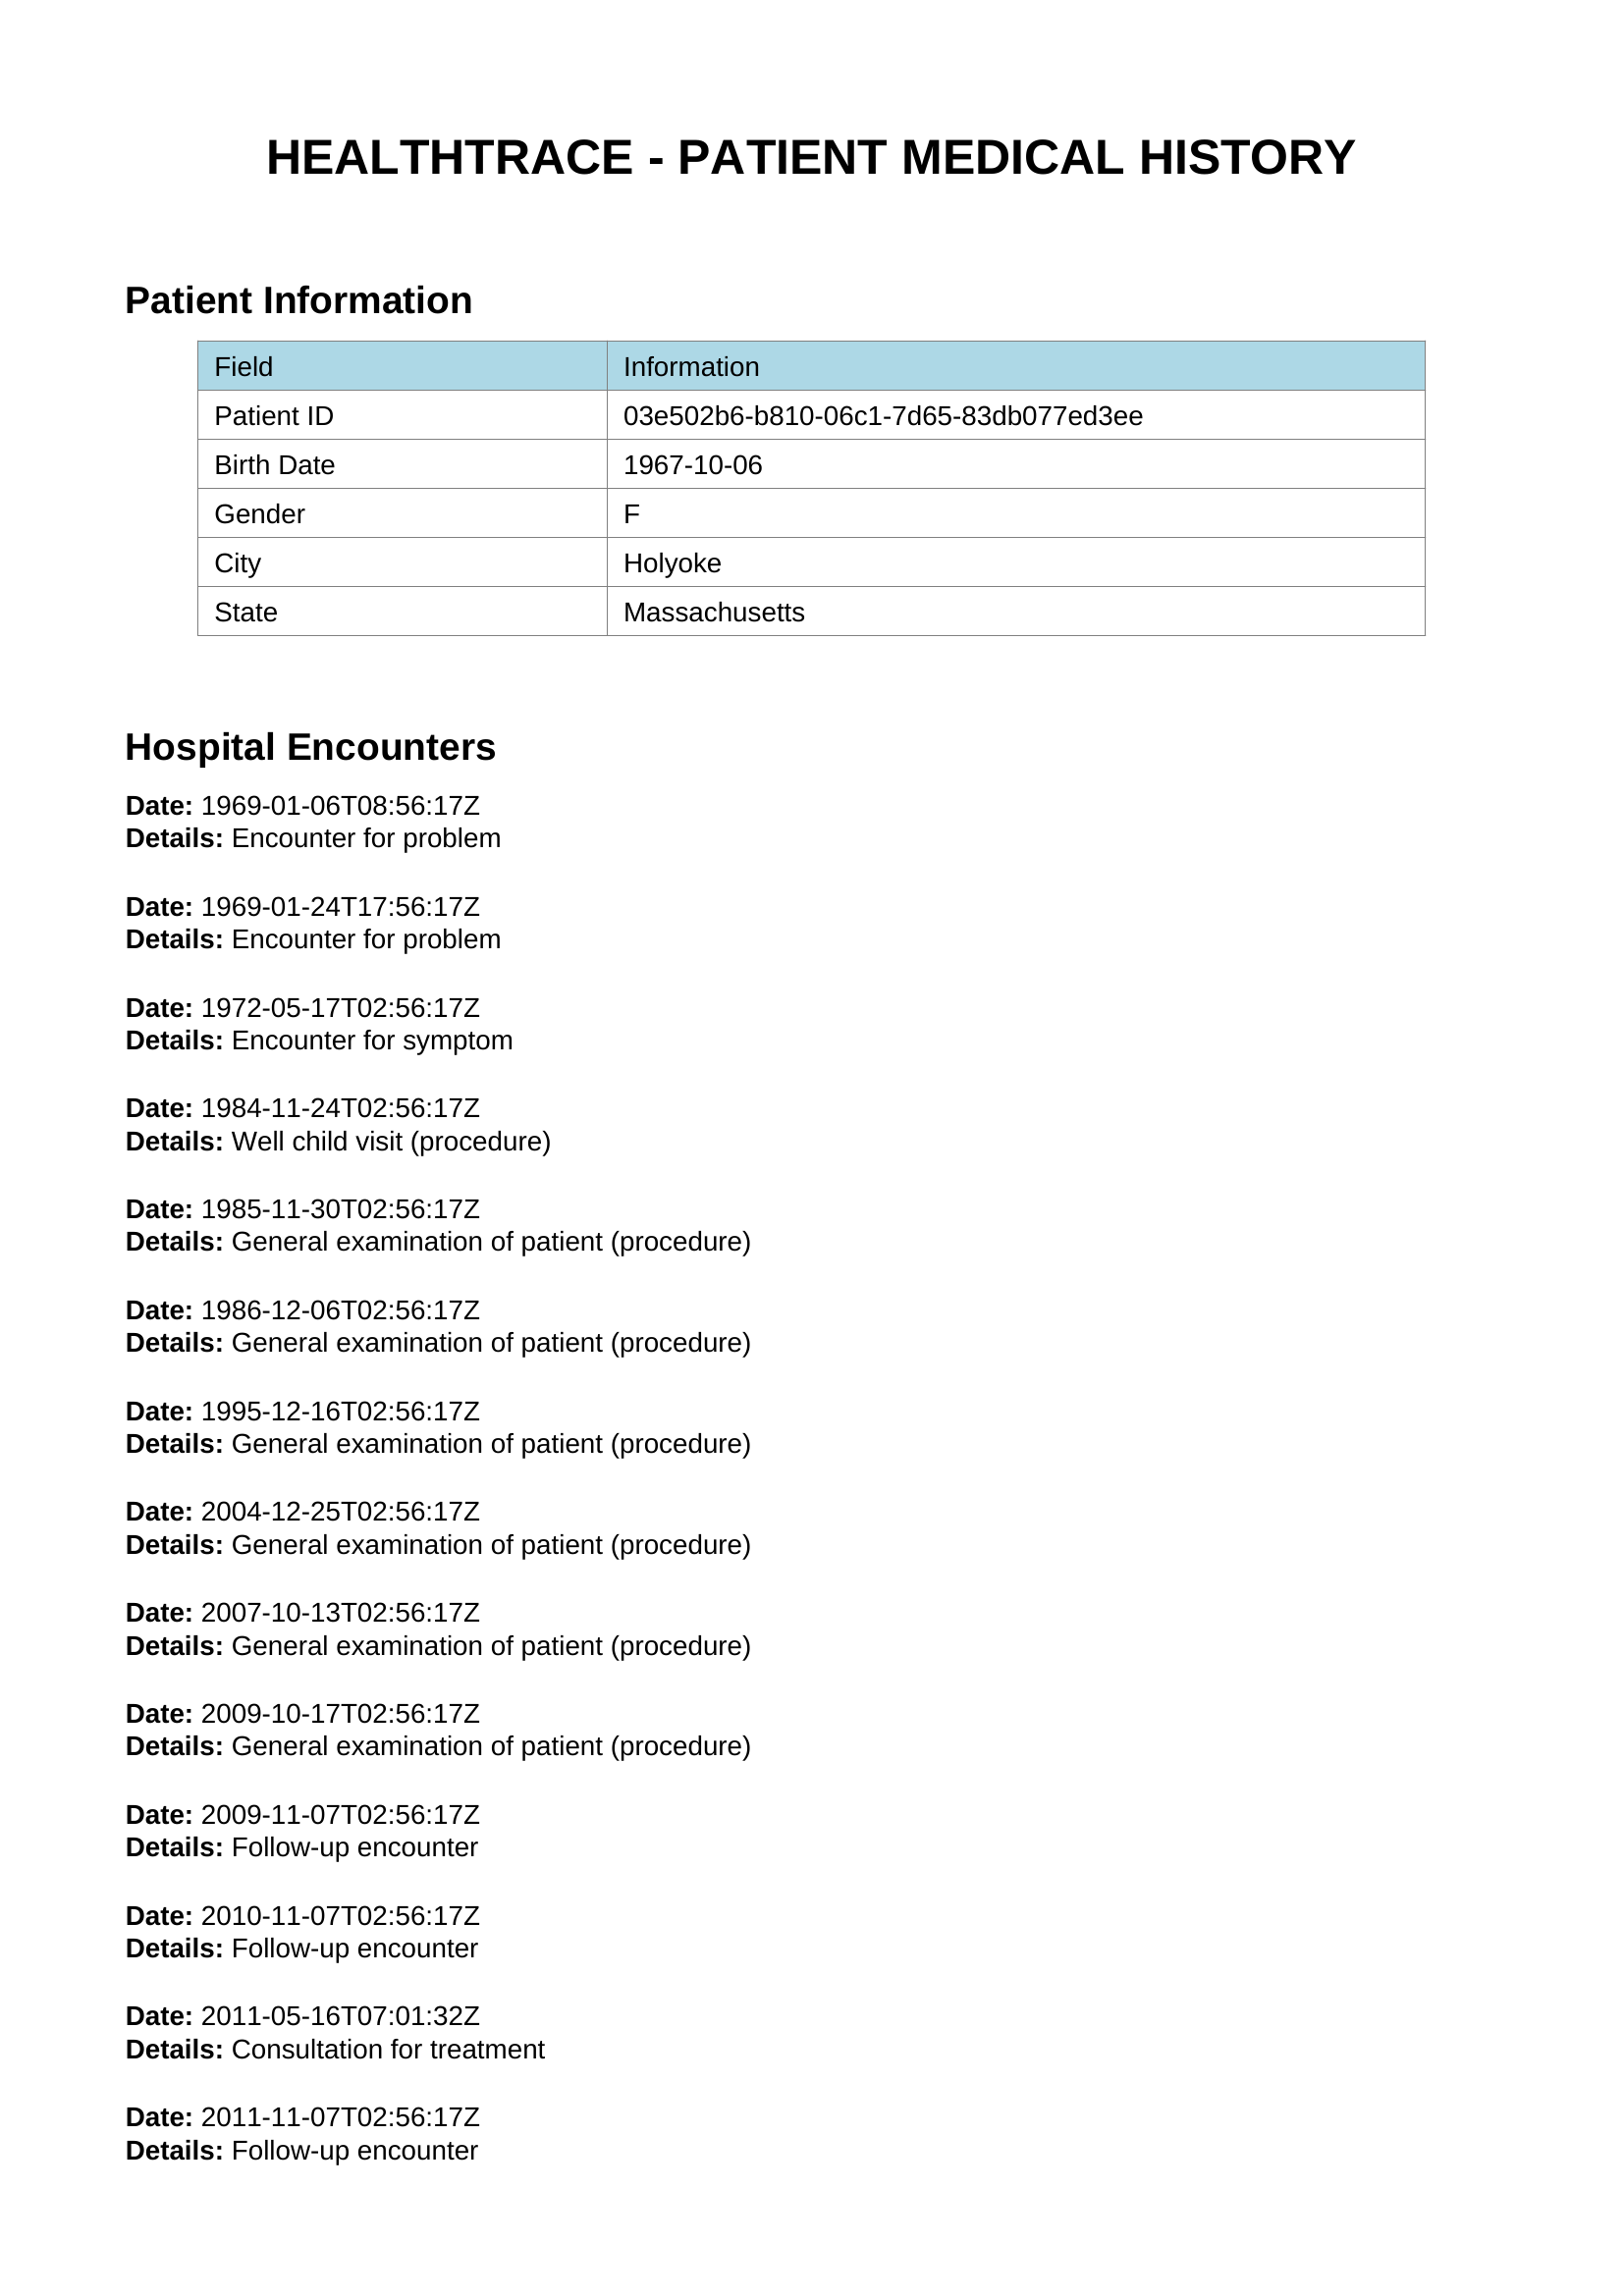

In [26]:
from pdf2image import convert_from_path

pages = convert_from_path(
    report_path,
    dpi=200
)

print("Total pages converted:", len(pages))

display(pages[0])

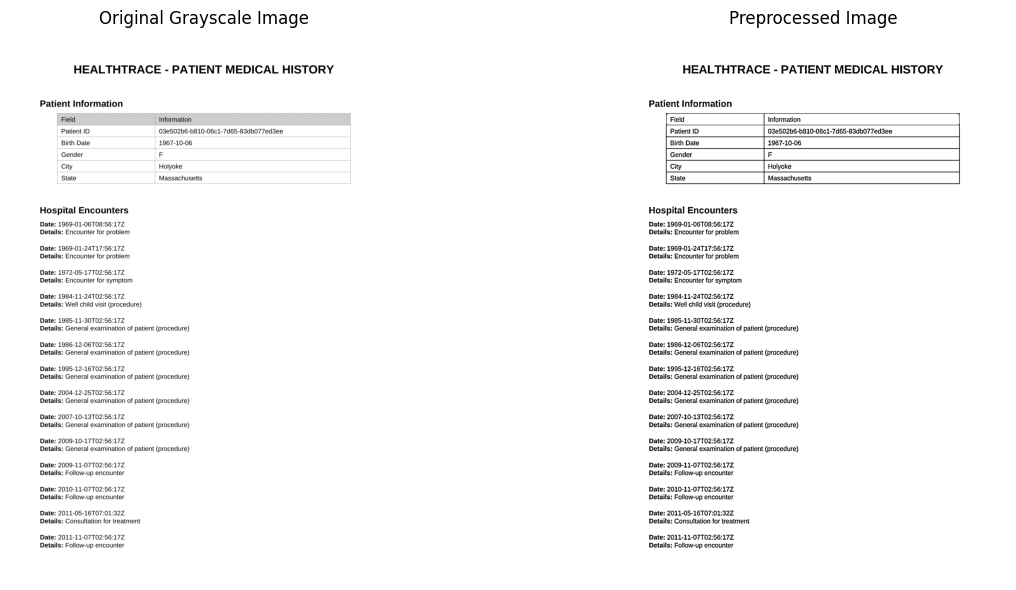

In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Convert the first PDF page into a NumPy array
image = np.array(pages[0])

# Convert RGB to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Remove noise
denoised = cv2.GaussianBlur(gray, (3, 3), 0)

# Apply adaptive thresholding
processed_image = cv2.adaptiveThreshold(
    denoised,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    31,
    11
)

# Display original and processed images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(processed_image, cmap="gray")
plt.title("Preprocessed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [28]:
import pytesseract

ocr_text = pytesseract.image_to_string(
    processed_image,
    config="--psm 6"
)

print("OCR Extracted Text:\n")
print(ocr_text)

print("\nOCR Characters:", len(ocr_text))

OCR Extracted Text:

HEALTHTRACE - PATIENT MEDICAL HISTORY
Patient Information
[Fed i oration SSCS~S~SCSY
03e502b6-b810-06c1-7d65-83db077ed3ee
Hospital Encounters
Date: 1969-01-06T08:56:17Z
Details: Encounter for problem
Date: 1969-01-24T17:56:17Z
Details: Encounter for problem
Date: 1972-05-17T02:56:17Z
Details: Encounter for symptom
Date: 1984-11-24T02:56:17Z
Details: Well child visit (procedure)
Date: 1985-11-30T02:56:17Z
Details: General examination of patient (procedure)
Date: 1986-12-06T02:56:17Z
Details: General examination of patient (procedure)
Date: 1995-12-16T02:56:17Z
Details: General examination of patient (procedure)
Date: 2004-12-25T02:56:17Z
Details: General examination of patient (procedure)
Date: 2007-10-13T02:56:17Z
Details: General examination of patient (procedure)
Date: 2009-10-17T02:56:17Z
Details: General examination of patient (procedure)
Date: 2009-11-07T02:56:17Z
Details: Follow-up encounter
Date: 2010-11-07T02:56:17Z
Details: Follow-up encounter
Date: 2011-0